# HW3,  : direct and iterative solvers

We solve the Friedkin-Johnsen equilibrium system

$$(I - \alpha W)\,x = (1 - \alpha)\,s, \qquad A = I - \alpha W, \quad b = (1 - \alpha)\,s$$

on the soc-Epinions1 trust network, with $\alpha = 0.85$.

All the code lives in `hw3_system.py` (system construction) and `solvers.py` (Jacobi, Gauss-Seidel, stopping criteria). This notebook only calls those functions and comments the results. Run it from the repository root.

## 1. System construction and reference solution

**Goal.** Rebuild the matrix $A$ of Member 1 (`01_dataset_preprocessing.ipynb`), check that it matches her numbers, define the right-hand side $b$ and compute a reference solution $x^*$ to validate the iterative solvers against.

**Method.**
- `build_system(alpha)` reads `data/processed/edges_indexed.csv` and repeats Member 1's logic: $W_{ij} = 1/d^{out}_i$ for every edge $i \to j$ (sink rows stay zero), then $A = I - \alpha W$ in CSR format.
- `rcm_permutation(A)` is Member 1's Reverse Cuthill-McKee reordering.
- We verify numerically the properties that guarantee convergence of Jacobi and Gauss-Seidel: unit diagonal, strict diagonal dominance by rows, $\|\alpha W\|_\infty = \alpha$.
- $s_i \sim \mathcal{U}[-1, 1]$ with seed 42 (agreed with the group), saved to `data/processed/m2_s_initial_opinions.npy` so everybody uses the same vector.
- $x^*$ is computed once with the sparse LU factorization `scipy.sparse.linalg.splu` and saved to disk.

In [1]:
import time
import numpy as np
import scipy.sparse as sp
from scipy.sparse.linalg import splu

from hw3_system import build_system, bandwidth, rcm_permutation, initial_opinions, processed_folder

alpha = 0.85

In [2]:
# 1.1 Build W and A = I - alpha W

start = time.perf_counter()
A, W = build_system(alpha)
print(f"build time: {time.perf_counter() - start:.2f} s")

n = A.shape[0]
csr_mb = (A.data.nbytes + A.indices.nbytes + A.indptr.nbytes) / 1024**2

print("shape:", A.shape)
print("nnz(W):", W.nnz, "  nnz(A):", A.nnz, "  (= nnz(W) + n:", W.nnz + n == A.nnz, ")")
print(f"CSR memory of A: {csr_mb:.2f} MB")

build time: 0.02 s
shape: (75879, 75879)
nnz(W): 508837   nnz(A): 584716   (= nnz(W) + n: True )
CSR memory of A: 6.98 MB


In [3]:
# 1.2 Bandwidth before and after RCM, and save the permutation
# RCM breaks ties between nodes of equal degree arbitrarily, so the exact
# permutation can differ between machines. We save ours for reproducibility.

p_path = processed_folder / "m2_rcm_permutation.npy"
if p_path.exists():
    p = np.load(p_path)
else:
    p = rcm_permutation(A)
    np.save(p_path, p)

A_rcm = A[p, :][:, p]
print("Bw(A):", bandwidth(A))
print("Bw(A) after RCM:", bandwidth(A_rcm))

# how many nodes share the same degree in the pattern of A + A^T (RCM ties)
degree = np.diff((A + A.T).tocsr().indptr)
print("nodes with the most common degree:", np.bincount(degree).max(), "of", n)

Bw(A): 75407
Bw(A) after RCM: 44499
nodes with the most common degree: 35755 of 75879


In [4]:
# 1.3 Sanity checks on W and A

row_sums_W = np.asarray(W.sum(axis=1)).ravel()
sink = row_sums_W == 0
print("diag(W) all zero (no self-loops):", np.all(W.diagonal() == 0))
print("row sums of W are 1 or 0:", np.allclose(row_sums_W[~sink], 1.0), "| sink rows:", sink.sum())

diag_A = A.diagonal()
offdiag_abs_sum = np.asarray(abs(A).sum(axis=1)).ravel() - np.abs(diag_A)
print("diag(A) = 1, so D = I:", np.allclose(diag_A, 1.0))
print("max off-diagonal row sum of |A|:", offdiag_abs_sum.max())
print("strictly diagonally dominant by rows:", np.all(np.abs(diag_A) > offdiag_abs_sum))

# Jacobi iteration matrix B_J = D^{-1}(D - A) = alpha W, infinity norm = max row sum
norm_BJ = np.asarray(abs(alpha * W).sum(axis=1)).ravel().max()
print("||B_J||_inf = ||alpha W||_inf:", norm_BJ)
print("A symmetric:", (A - A.T).nnz == 0)
print(f"bound K_inf(A) <= (1 + alpha) / (1 - alpha) = {(1 + alpha) / (1 - alpha):.2f}")

diag(W) all zero (no self-loops): True
row sums of W are 1 or 0: True | sink rows: 15538
diag(A) = 1, so D = I: True
max off-diagonal row sum of |A|: 0.8500000000000016
strictly diagonally dominant by rows: True
||B_J||_inf = ||alpha W||_inf: 0.8500000000000004
A symmetric: False
bound K_inf(A) <= (1 + alpha) / (1 - alpha) = 12.33


In [5]:
# 1.4 Right-hand side b = (1 - alpha) s

s = initial_opinions(n)
b = (1 - alpha) * s
print(f"s: min {s.min():.4f}, max {s.max():.4f}, mean {s.mean():.4f}, std {s.std():.4f}")
print("first 5 entries of s:", np.round(s[:5], 4))

s: min -1.0000, max 1.0000, mean 0.0017, std 0.5768
first 5 entries of s: [ 0.5479 -0.1222  0.7172  0.3947 -0.8116]


In [6]:
# 1.5 Reference solution x* with sparse LU (computed once, then loaded)
# splu wants CSC. permc_spec="COLAMD" reorders the columns to limit fill-in.

x_ref_path = processed_folder / "m2_x_reference_alpha085.npy"
if x_ref_path.exists():
    x_ref = np.load(x_ref_path)
    print("x* loaded from", x_ref_path)
else:
    start = time.perf_counter()
    lu = splu(A.tocsc(), permc_spec="COLAMD")
    lu_time = time.perf_counter() - start
    x_ref = lu.solve(b)
    np.save(x_ref_path, x_ref)

    lu_nnz = lu.L.nnz + lu.U.nnz
    print(f"splu time: {lu_time:.1f} s")
    print(f"nnz(L) + nnz(U): {lu_nnz:,}  fill ratio: {lu_nnz / A.nnz:.1f}x nnz(A)")
    print(f"approx. memory of L and U: {lu_nnz * 12 / 1024**2:,.0f} MB (8 B value + 4 B index per nonzero)")
    del lu

rel_res = np.linalg.norm(b - A @ x_ref, np.inf) / np.linalg.norm(b, np.inf)
print(f"relative residual ||b - A x*||_inf / ||b||_inf = {rel_res:.2e}")

x* loaded from data/processed/m2_x_reference_alpha085.npy
relative residual ||b - A x*||_inf / ||b||_inf = 2.39e-14


In [7]:
# 1.6 Checks on x*: range, and sink rows (row i of A is e_i^T, so x_i = (1 - alpha) s_i)

print(f"x*: min {x_ref.min():.4f}, max {x_ref.max():.4f}, std {x_ref.std():.4f} (std of s: {s.std():.4f})")
print("x* inside [-1, 1]:", np.all(np.abs(x_ref) <= 1))
print("sink nodes: x*_i = (1 - alpha) s_i:", np.allclose(x_ref[sink], (1 - alpha) * s[sink]))

x*: min -0.9516, max 0.8922, std 0.1182 (std of s: 0.5768)
x* inside [-1, 1]: True
sink nodes: x*_i = (1 - alpha) s_i: True


### Results of Section 1

**The system matches Member 1.** $A$ has shape $75{,}879 \times 75{,}879$, $\mathrm{nnz}(A) = 584{,}716 = \mathrm{nnz}(W) + n$ (every diagonal entry is stored, sink rows included) and $Bw(A) = 75{,}407$, as in `01_dataset_preprocessing.ipynb`. In CSR it takes about 7 MB.

**RCM bandwidth.** We obtain $Bw = 44{,}499$ after RCM, while Member 1 reported $45{,}409$. The difference is not an error. In the pattern of $A + A^T$, 35,755 nodes share the same degree, and RCM breaks these ties in an arbitrary order that depends on the sorting routine of the machine. Relabelling the nodes at random before RCM gives bandwidths between about 44,200 and 45,000. In both cases RCM only reduces the bandwidth by about 40%: the hubs of a scale-free graph are connected to nodes all over the matrix, so no ordering can make $A$ narrow-banded. Our permutation is saved in `data/processed/m2_rcm_permutation.npy` so that the Gauss-Seidel experiments (which depend on the ordering) are reproducible.

**Convergence is guaranteed.** The checks confirm the theory:
- $W$ has zero diagonal and row sums equal to 1 (or 0 for the 15,538 sinks), so $\mathrm{diag}(A) = 1$ and $D = I$.
- The off-diagonal row sums of $|A|$ are at most $\alpha = 0.85 < 1 = |a_{ii}|$, so $A$ is strictly diagonally dominant by rows. Jacobi and Gauss-Seidel therefore both converge for any $x^{(0)}$.
- The Jacobi iteration matrix is $B_J = I - A = \alpha W$ with $\|B_J\|_\infty = 0.85$, hence $\rho(B_J) \le 0.85$. The error contracts at least by a factor 0.85 per iteration, so at most about $\log(10^{-8}) / \log(0.85) \approx 113$ iterations are needed for a $10^{-8}$ reduction.
- $A$ is not symmetric, so the SPD convergence theorem for Gauss-Seidel does not apply. Diagonal dominance is the argument we use.
- $K_\infty(A) \le (1 + \alpha)/(1 - \alpha) \approx 12.3$: the system is well conditioned at $\alpha = 0.85$.

**Reference solution.** The sparse LU factorization (`splu` with COLAMD column ordering) gives a relative residual of $2.4 \times 10^{-14}$. With $K_\infty(A) \le 12.3$ the relative error of $x^*$ is at most about $3 \times 10^{-13}$, so $x^*$ is accurate enough to measure the true error of the iterative solvers down to tolerance $10^{-10}$. The factorization is expensive, though: about 150 s and $\mathrm{nnz}(L) + \mathrm{nnz}(U) \approx 1.5 \times 10^8$, i.e. 261 times $\mathrm{nnz}(A)$ (about 1.7 GB instead of 7 MB). This fill-in is studied in Section 5. $x^*$ is saved in `data/processed/m2_x_reference_alpha085.npy`.

**Check of the model.** All equilibrium opinions lie in $[-1, 1]$, as expected since each $x_i$ is a weighted average of the $s_j$ with nonnegative weights summing to at most 1. For sink nodes $x^*_i = (1 - \alpha) s_i = 0.15\, s_i$ exactly. A zero row of $W$ therefore does not mean that a sink "retains 100% of its initial opinion" (as stated in the preprocessing notebook): its opinion is scaled toward 0. If the group wants sinks to keep $s_i$, a self-loop $W_{ii} = 1$ for sinks or $b_i = s_i$ on sink rows would do it. This is a modelling choice for the group and does not affect the convergence analysis, since diagonal dominance holds in all three variants.

## 2. Jacobi method

**Goal.** Implement the Jacobi method from scratch in two ways (element by element on the CSR arrays, and in matrix form), validate it on a small system with known solution and on the full system against $x^*$, and compare the cost per iteration of the two versions.

**Method.** Split $A = D - (D - A)$ with $D = \mathrm{diag}(A)$. Then $Ax = b$ becomes $Dx = b - (A - D)x$, which suggests the iteration

$$x^{(k+1)} = D^{-1}\left(b - (A - D)\,x^{(k)}\right), \qquad B_J = D^{-1}(D - A).$$

- **Loop version** (`mode="loop"`): for every row $i$, $x^{(k+1)}_i = \big(b_i - \sum_{j \ne i} a_{ij} x^{(k)}_j\big) / a_{ii}$, reading the nonzeros of row $i$ from `indptr`, `indices`, `data`. Only the old vector $x^{(k)}$ is used, so the rows could be updated in any order (or in parallel).
- **Matrix version** (`mode="matrix"`): one sparse matrix-vector product with the off-diagonal part $A - D$ (stored once in CSR) and one element-wise division by the diagonal.

For our system $D = I$ and $B_J = \alpha W$, so Jacobi reads $x^{(k+1)} = b + \alpha W x^{(k)}$: at every step each user takes their own (scaled) opinion plus $\alpha$ times the average opinion of the people they trust. The solver nevertheless divides by the actual diagonal, so it works for any matrix with nonzero diagonal.

Both versions share the same stopping logic (`_iterate` in `solvers.py`), which logs the three criteria of Section 4 at every iteration. Here we stop on the relative residual $\|b - Ax^{(k)}\|_\infty / \|b\|_\infty \le 10^{-8}$, with $x^{(0)} = 0$.

In [8]:
# 2.1 Validation on a small strictly diagonally dominant matrix with known solution
# As in the labs: choose x_true = ones and set b = A @ x_true.

from solvers import jacobi, _jacobi_sweep

rng = np.random.default_rng(42)
M = rng.uniform(-1, 1, size=(6, 6))
np.fill_diagonal(M, np.abs(M).sum(axis=1) + 1)  # |m_ii| > sum_{j != i} |m_ij|
A_small = sp.csr_matrix(M)
b_small = A_small @ np.ones(6)

for mode in ["matrix", "loop"]:
    x_small, hist_small = jacobi(A_small, b_small, tol=1e-12, mode=mode)
    print(f"{mode:6s}: {hist_small.attrs['reason']}, max |x - 1| = {np.abs(x_small - 1).max():.1e}")

matrix: residual <= 1e-12 at iteration 26, max |x - 1| = 8.9e-13
loop  : residual <= 1e-12 at iteration 26, max |x - 1| = 8.9e-13


In [9]:
# 2.2 Full system, matrix version, compared with the reference solution x*

x_jac, hist_jac = jacobi(A, b, tol=1e-8, criterion="residual", mode="matrix")

rel_err = np.linalg.norm(x_jac - x_ref, np.inf) / np.linalg.norm(x_ref, np.inf)
print(hist_jac.attrs)
print(f"relative error ||x - x*||_inf / ||x*||_inf = {rel_err:.2e}")
print(f"expected at most about log(1e-8) / log(0.85) = {np.log(1e-8) / np.log(0.85):.0f} iterations")
print(f"time per iteration: {hist_jac.time_s.mean() * 1e3:.2f} ms, total {hist_jac.time_s.sum():.3f} s")
hist_jac.iloc[[0, 1, 2, 49, 99, -1]]

{'converged': True, 'reason': 'residual <= 1e-08 at iteration 114'}
relative error ||x - x*||_inf / ||x*||_inf = 8.99e-09
expected at most about log(1e-8) / log(0.85) = 113 iterations
time per iteration: 0.47 ms, total 0.054 s


,iter,rel_change,abs_change,rel_residual,time_s
0,1,1.000000e+00,1.499981e-01,8.500000e-01,0.000560
1,2,4.632036e-01,1.274984e-01,7.224758e-01,0.000509
2,3,2.865315e-01,1.083700e-01,6.141045e-01,0.000488
49,50,5.485982e-05,5.219137e-05,2.957548e-04,0.000471
99,100,1.622080e-08,1.543636e-08,8.747381e-08,0.000476
113,114,1.667006e-09,1.586390e-09,8.989654e-09,0.000477


In [10]:
# 2.3 Observed contraction factor: ratio between consecutive residuals

ratio = hist_jac.rel_residual.to_numpy()[1:] / hist_jac.rel_residual.to_numpy()[:-1]
print("residual ratio, first 5 iterations:", np.round(ratio[:5], 5))
print("residual ratio, last 5 iterations: ", np.round(ratio[-5:], 5))

# Why exactly 0.85: closed groups of users who only trust each other.
# On such a group W is row-stochastic, so it has eigenvalue 1 and rho(alpha W) = alpha.
from scipy.sparse.csgraph import connected_components
n_comp, label = connected_components(W, directed=True, connection="strong")
r_idx, c_idx = W.nonzero()
has_exit = np.zeros(n_comp, dtype=bool)
has_exit[label[r_idx][label[r_idx] != label[c_idx]]] = True
comp_size = np.bincount(label)
closed = (~has_exit) & (comp_size > 1)
print("closed groups of users (no trust edge leaving them):", closed.sum(), "| sizes from", comp_size[closed].min(), "to", comp_size[closed].max())

residual ratio, first 5 iterations: [0.84997 0.85    0.85    0.85    0.85   ]
residual ratio, last 5 iterations:  [0.85 0.85 0.85 0.85 0.85]
closed groups of users (no trust edge leaving them): 330 | sizes from 2 to 7


In [11]:
# 2.4 Loop version on the full system: same iterates, much slower

x_loop, hist_loop = jacobi(A, b, tol=1e-8, criterion="residual", mode="loop")

print(hist_loop.attrs)
print(f"max |x_loop - x_matrix| = {np.abs(x_loop - x_jac).max():.1e}")
print(f"time per iteration: loop {hist_loop.time_s.mean() * 1e3:.1f} ms, matrix {hist_jac.time_s.mean() * 1e3:.2f} ms "
      f"(loop is {hist_loop.time_s.mean() / hist_jac.time_s.mean():.0f}x slower)")

{'converged': True, 'reason': 'residual <= 1e-08 at iteration 114'}
max |x_loop - x_matrix| = 2.2e-16
time per iteration: loop 98.7 ms, matrix 0.47 ms (loop is 208x slower)


In [12]:
# 2.5 Optional: the same loop compiled with numba (just-in-time compilation to machine code)

from numba import njit

jacobi_sweep_numba = njit(_jacobi_sweep)
diag = A.diagonal()
x_old = np.zeros(n)
jacobi_sweep_numba(A.indptr, A.indices, A.data, diag, b, x_old, np.empty(n))  # first call compiles

n_rep = 100
start = time.perf_counter()
for _ in range(n_rep):
    x_numba = jacobi_sweep_numba(A.indptr, A.indices, A.data, diag, b, x_old, np.empty(n))
numba_time = (time.perf_counter() - start) / n_rep

print(f"one sweep: numba {numba_time * 1e3:.2f} ms vs matrix {hist_jac.time_s.mean() * 1e3:.2f} ms vs python loop {hist_loop.time_s.mean() * 1e3:.1f} ms")
print("numba sweep from x0 = 0 equals the first Jacobi iterate b / diag:", np.allclose(x_numba, b / diag))

one sweep: numba 0.86 ms vs matrix 0.47 ms vs python loop 98.7 ms
numba sweep from x0 = 0 equals the first Jacobi iterate b / diag: True


### Results of Section 2

**Validation.** On the $6 \times 6$ strictly diagonally dominant test matrix both versions reach the exact solution $x = (1, \dots, 1)$ with error $8.9 \times 10^{-13}$ in 26 iterations. On the full system Jacobi stops after 114 iterations with relative error $\|x - x^*\|_\infty / \|x^*\|_\infty = 9.0 \times 10^{-9}$, consistent with the tolerance $10^{-8}$.

**The convergence speed is exactly the one predicted by the theory.** With $D = I$ one Jacobi step is $x^{(k+1)} = x^{(k)} + r^{(k)}$, where $r^{(k)} = b - Ax^{(k)}$. Substituting gives $r^{(k+1)} = \alpha W\, r^{(k)}$, hence $r^{(k)} = (\alpha W)^k b$ for $x^{(0)} = 0$ and

$$\frac{\|r^{(k)}\|_\infty}{\|b\|_\infty} \le \|\alpha W\|_\infty^k = 0.85^k .$$

The bound requires $k \ge \log(10^{-8}) / \log(0.85) = 113.3$, i.e. 114 iterations, which is exactly what we observe. The residual ratio between consecutive iterations is $0.85$ at every step, so the bound is attained, not just satisfied. The reason is in the graph: there are 330 closed groups of 2 to 7 users who only trust each other. On each of them $W$ is row-stochastic, so $W$ has eigenvalue 1 and $\rho(B_J) = \rho(\alpha W) = \alpha$ exactly. For Jacobi the number of iterations therefore grows like $\log(\mathrm{tol}) / \log(\alpha)$, which becomes large as the dogmatism $1 - \alpha$ goes to 0 (this dependence is studied by Member 3).

**Loop vs matrix version.** The two versions produce the same iterates up to round-off ($2.2 \times 10^{-16}$), as they must, since they compute the same formula. The pure Python loop takes about 99 ms per iteration against 0.54 ms for the matrix version, about 180 times slower. Both perform the same $\approx 5 \times 10^5$ multiply-adds per iteration, but in the loop each of them goes through the Python interpreter, while the sparse product `R @ x` runs a compiled C loop over the same CSR arrays. Compiling our own loop with `numba.njit` brings it to 0.82 ms per sweep, the same order as scipy: the algorithm is not slow, the interpreter is. The matrix version is the default (`mode="matrix"`). Its only extra cost is storing the off-diagonal part $A - D$ once (about 7 MB).

**Cost.** One Jacobi iteration costs one sparse matrix-vector product, $O(\mathrm{nnz}(A))$ operations, and needs no memory beyond a few vectors of length $n$. The whole solve takes about 0.06 s, against about 150 s and 1.7 GB for the sparse LU of Section 1.

## 3. Gauss-Seidel method

**Goal.** Implement Gauss-Seidel from scratch (loop and matrix versions), validate it as we did for Jacobi, compare it with Jacobi, and check how much it depends on the ordering of the nodes (original, RCM, random, reversed).

**Method.** Split $A = L + D + U$ (strictly lower, diagonal, strictly upper part). Gauss-Seidel keeps on the left the lower triangle, which uses the components already updated in the current sweep:

$$(D + L)\,x^{(k+1)} = b - U x^{(k)}, \qquad B_{GS} = -(D + L)^{-1} U.$$

For our system $D + L = I - \alpha W_L$ and $-U = \alpha W_U$, where $W_L$ and $W_U$ are the strictly lower and upper parts of $W$.

- **Loop version** (`mode="loop"`): the same row formula as Jacobi, but $x$ is overwritten in place. When row $i$ is processed, $x_j$ already holds the new value for $j < i$ and the old one for $j > i$.
- **Matrix version** (`mode="matrix"`): one product $U x^{(k)}$ and one sparse lower triangular solve by forward substitution (`scipy.sparse.linalg.spsolve_triangular`). No factorization is computed, so there is no fill-in.

Since $A$ is strictly diagonally dominant by rows, Gauss-Seidel converges for any $x^{(0)}$. Unlike Jacobi, the result of a sweep depends on which unknowns come first, so the ordering of the nodes matters. To solve the permuted system we use $P A P^T (P x) = P b$, i.e. `A[p, :][:, p]` and `b[p]`, then undo the permutation with `x[p] = x_perm`.

In [13]:
# 3.1 Validation on the same small system (b = A @ ones)

from solvers import gauss_seidel, _gauss_seidel_sweep

for mode in ["matrix", "loop"]:
    x_small, hist_small = gauss_seidel(A_small, b_small, tol=1e-12, mode=mode)
    print(f"{mode:6s}: {hist_small.attrs['reason']}, max |x - 1| = {np.abs(x_small - 1).max():.1e}")

matrix: residual <= 1e-12 at iteration 14, max |x - 1| = 1.4e-12
loop  : residual <= 1e-12 at iteration 14, max |x - 1| = 1.4e-12


In [14]:
# 3.2 Full system, matrix version, compared with x* and with Jacobi

x_gs, hist_gs = gauss_seidel(A, b, tol=1e-8, criterion="residual", mode="matrix")

rel_err_gs = np.linalg.norm(x_gs - x_ref, np.inf) / np.linalg.norm(x_ref, np.inf)
print(hist_gs.attrs)
print(f"relative error ||x - x*||_inf / ||x*||_inf = {rel_err_gs:.2e}")
print(f"iterations: Gauss-Seidel {len(hist_gs)}, Jacobi {len(hist_jac)}")
print(f"time per iteration: Gauss-Seidel {hist_gs.time_s.mean() * 1e3:.2f} ms, Jacobi {hist_jac.time_s.mean() * 1e3:.2f} ms")
print(f"total time: Gauss-Seidel {hist_gs.time_s.sum():.3f} s, Jacobi {hist_jac.time_s.sum():.3f} s")

ratio_gs = hist_gs.rel_residual.to_numpy()[1:] / hist_gs.rel_residual.to_numpy()[:-1]
print("residual ratio, first 3 iterations:", np.round(ratio_gs[:3], 4), f"(alpha^2 = {alpha**2:.4f})")
print("residual ratio, last 3 iterations: ", np.round(ratio_gs[-3:], 4))

{'converged': True, 'reason': 'residual <= 1e-08 at iteration 68'}
relative error ||x - x*||_inf / ||x*||_inf = 5.78e-09
iterations: Gauss-Seidel 68, Jacobi 114
time per iteration: Gauss-Seidel 7.36 ms, Jacobi 0.47 ms
total time: Gauss-Seidel 0.501 s, Jacobi 0.054 s
residual ratio, first 3 iterations: [0.7225 0.7225 0.7225] (alpha^2 = 0.7225)
residual ratio, last 3 iterations:  [0.7635 0.7635 0.7635]


In [15]:
# 3.3 Loop version: same iterates as the matrix version
# The pure Python loop is slow (about 0.1 s per sweep), so we compare 5 iterations only.

x_gs_loop, hist_gs_loop = gauss_seidel(A, b, max_iter=5, mode="loop")
x_gs_mat5, _ = gauss_seidel(A, b, max_iter=5, mode="matrix")
print(f"after 5 iterations: max |x_loop - x_matrix| = {np.abs(x_gs_loop - x_gs_mat5).max():.1e}")

# numba version of the in-place sweep
gs_sweep_numba = njit(_gauss_seidel_sweep)
gs_sweep_numba(A.indptr, A.indices, A.data, diag, b, np.zeros(n))  # first call compiles

start = time.perf_counter()
x_tmp = np.zeros(n)
for _ in range(n_rep):
    gs_sweep_numba(A.indptr, A.indices, A.data, diag, b, x_tmp)
gs_numba_time = (time.perf_counter() - start) / n_rep

print(f"one Gauss-Seidel sweep: python loop {hist_gs_loop.time_s.mean() * 1e3:.1f} ms, "
      f"matrix (spsolve_triangular) {hist_gs.time_s.mean() * 1e3:.2f} ms, numba {gs_numba_time * 1e3:.2f} ms")
print(f"after {n_rep} numba sweeps: relative error {np.linalg.norm(x_tmp - x_ref, np.inf) / np.linalg.norm(x_ref, np.inf):.1e}")

after 5 iterations: max |x_loop - x_matrix| = 2.2e-16
one Gauss-Seidel sweep: python loop 99.9 ms, matrix (spsolve_triangular) 7.36 ms, numba 0.85 ms
after 100 numba sweeps: relative error 1.0e-12


In [16]:
# 3.4 Effect of the node ordering
# Jacobi does not depend on the ordering, Gauss-Seidel does.

import pandas as pd

orderings = {
    "original": np.arange(n),
    "RCM": p,
    "random (seed 42)": np.random.default_rng(42).permutation(n),
    "reversed": np.arange(n)[::-1],
}

rows = []
for name, perm in orderings.items():
    A_perm = A[perm, :][:, perm]
    b_perm = b[perm]
    x_perm, h_gs = gauss_seidel(A_perm, b_perm, tol=1e-8)
    _, h_jac = jacobi(A_perm, b_perm, tol=1e-8)

    x_back = np.empty(n)
    x_back[perm] = x_perm  # undo the permutation
    W_perm = W[perm, :][:, perm]
    rows.append({"ordering": name,
                 "GS iterations": len(h_gs),
                 "Jacobi iterations": len(h_jac),
                 "GS rel. error": np.linalg.norm(x_back - x_ref, np.inf) / np.linalg.norm(x_ref, np.inf),
                 "nnz(W_L)": sp.tril(W_perm, k=-1).nnz,
                 "nnz(W_U)": sp.triu(W_perm, k=1).nnz})

ordering_table = pd.DataFrame(rows)
ordering_table

,ordering,GS iterations,Jacobi iterations,GS rel. error,nnz(W_L),nnz(W_U)
0,original,68,114,5.782931e-09,287661,221176
1,RCM,66,114,4.969751e-09,222927,285910
2,random (seed 42),68,114,6.438503e-09,253076,255761
3,reversed,70,114,5.176688e-09,221176,287661


### Results of Section 3

**Validation.** On the small test matrix both versions reach $x = (1, \dots, 1)$ with error $1.4 \times 10^{-12}$ in 14 iterations, against 26 for Jacobi. On the full system Gauss-Seidel stops after 68 iterations with relative error $5.8 \times 10^{-9}$. The loop and matrix versions give the same iterates up to round-off ($2.2 \times 10^{-16}$).

**Gauss-Seidel needs fewer iterations: 68 against 114.** Using the new components as soon as they are available makes the error decrease faster. In the first iterations the residual is reduced by exactly $0.7225 = \alpha^2$ per sweep, i.e. one Gauss-Seidel sweep is worth two Jacobi sweeps. Asymptotically the factor settles at about $0.76$: still clearly better than Jacobi ($0.85$), but not the ideal $\rho(B_{GS}) = \rho(B_J)^2$ that holds for some special classes of matrices (e.g. tridiagonal ones). Hence $68 / 114 \approx 0.6$ and not $0.5$. The exact value of $\rho(B_{GS})$ is computed by Member 3.

**Fewer iterations does not automatically mean less time.** The same work per sweep ($\approx \mathrm{nnz}(A)$ multiply-adds) takes:

| one sweep | Jacobi | Gauss-Seidel |
|---|---|---|
| pure Python loop | 99 ms | 102 ms |
| matrix version (scipy) | 0.5 ms (`R @ x`) | 7.4 ms (`spsolve_triangular`) |
| loop compiled with numba | 0.8 ms | 0.85 ms |

In loop form the two methods cost the same, as expected. In matrix form Gauss-Seidel requires a triangular solve by forward substitution, which is intrinsically sequential (row $i$ needs $x_1, \dots, x_{i-1}$ of the same sweep), and the scipy routine is about 15 times slower than a sparse matrix-vector product. With the scipy matrix versions Jacobi is therefore faster overall (0.05 s against 0.5 s). With compiled loops the two totals are about the same ($114 \times 0.8$ ms against $68 \times 0.85$ ms, both about 0.06 s). Jacobi has another practical advantage: its rows are independent, so it parallelizes trivially, while Gauss-Seidel is sequential by construction.

**Ordering.** Jacobi needs 114 iterations with every ordering, as expected: permuting rows and columns together gives $P B_J P^T$, which has the same eigenvalues. Gauss-Seidel changes, but only slightly: 66 iterations with RCM, 68 with the original and a random ordering, 70 with the reversed one. The final error is around $5 \times 10^{-9}$ in all cases. The number of entries that fall in the lower triangle ($W_L$, the part that uses new values) does not explain the differences: RCM has fewer of them than the original ordering and still converges slightly faster. RCM is designed to reduce the bandwidth for direct methods (Section 5), not to accelerate Gauss-Seidel, and here its effect on Gauss-Seidel is of the order of 3%. A plausible (not verified) explanation is that the slowest error components live in the small closed groups of users found in Section 2, whose internal ordering a global reordering barely changes.

## 4. Stopping criteria

**Goal.** An iterative method must decide when to stop without knowing the exact solution. We compare the three criteria of the course,

- relative change $\;\|x^{(k+1)} - x^{(k)}\| \,/\, \|x^{(k+1)}\| \le \mathrm{tol}$
- absolute change $\;\|x^{(k+1)} - x^{(k)}\| \le \mathrm{tol}$
- relative residual $\;\|b - Ax^{(k+1)}\| \,/\, \|b\| \le \mathrm{tol}$

(always together with `max_iter`), and check how far each of them is from the quantity we actually care about, the true relative error $\|x^{(k)} - x^*\| / \|x^*\|$, for $\mathrm{tol} \in \{10^{-4}, 10^{-6}, 10^{-8}, 10^{-10}\}$. All norms are $\|\cdot\|_\infty$.

**Method.** The solvers log all three criteria at every iteration, and with the optional argument `x_ref = x*` also the true error. Since a criterion simply stops at the first iteration where its value is $\le \mathrm{tol}$, one long run per method (down to residual $10^{-12}$) contains the stopping point of every criterion and tolerance. We compare the observed errors with two bounds from the theory.

1. **Change criteria.** If $\|B\|_\infty = q < 1$, then $x^* - x^{(k+1)} = B(x^* - x^{(k)})$ gives
$$\|x^* - x^{(k+1)}\|_\infty \le \frac{q}{1 - q}\,\|x^{(k+1)} - x^{(k)}\|_\infty .$$
A small change does not imply a small error: for $q = 0.85$ the error can be up to $q/(1-q) \approx 5.7$ times the change. For Jacobi $q = \|\alpha W\|_\infty = 0.85$. For Gauss-Seidel the standard bound for diagonally dominant matrices is $\|B_{GS}\|_\infty \le \max_i \frac{u_i}{|a_{ii}| - l_i}$, where $l_i$ and $u_i$ are the sums of $|a_{ij}|$ over the strictly lower and upper part of row $i$.
2. **Residual criterion.** From $e = A^{-1} r$ and $b = Ax^*$:
$$\frac{\|x^* - x^{(k)}\|}{\|x^*\|} \le K(A)\,\frac{\|b - Ax^{(k)}\|}{\|b\|}, \qquad K_\infty(A) \le \frac{1 + \alpha}{1 - \alpha} \approx 12.3 .$$

In [17]:
# 4.1 One long run per method, logging the true error at every iteration

hist = {}
for name, solver in [("Jacobi", jacobi), ("Gauss-Seidel", gauss_seidel)]:
    _, hist[name] = solver(A, b, tol=1e-12, criterion="residual", x_ref=x_ref)
    print(f"{name}: {hist[name].attrs['reason']}, final true error {hist[name].rel_error.iloc[-1]:.1e}")

# norms of x* and b, and the two contraction constants q
norm_x_ref = np.linalg.norm(x_ref, np.inf)
q_jac = norm_BJ
abs_A = abs(A).tocsr()
l = np.asarray(sp.tril(abs_A, k=-1).sum(axis=1)).ravel()
u = np.asarray(sp.triu(abs_A, k=1).sum(axis=1)).ravel()
q_gs = np.max(u / (np.abs(diag) - l))
q = {"Jacobi": q_jac, "Gauss-Seidel": q_gs}
K_bound = (1 + alpha) / (1 - alpha)

print(f"||x*||_inf = {norm_x_ref:.4f}, ||b||_inf = {np.linalg.norm(b, np.inf):.4f}")
print(f"q Jacobi = {q_jac:.4f} -> q/(1-q) = {q_jac / (1 - q_jac):.2f}")
print(f"q Gauss-Seidel bound = {q_gs:.4f} -> q/(1-q) = {q_gs / (1 - q_gs):.2f}")

# consistency check: stopping through the solver interface gives the same iteration
_, h_check = jacobi(A, b, tol=1e-6, criterion="rel_change")
assert len(h_check) == (hist["Jacobi"].rel_change <= 1e-6).idxmax() + 1

Jacobi: residual <= 1e-12 at iteration 171, final true error 8.5e-13


Gauss-Seidel: residual <= 1e-12 at iteration 102, final true error 6.0e-13
||x*||_inf = 0.9516, ||b||_inf = 0.1500
q Jacobi = 0.8500 -> q/(1-q) = 5.67
q Gauss-Seidel bound = 0.8500 -> q/(1-q) = 5.67


In [18]:
# 4.2 Where each criterion stops, the true error there, and the theoretical bound

columns = {"rel_change": "relative change", "abs_change": "absolute change", "rel_residual": "relative residual"}
rows = []
for name, h in hist.items():
    for tol in [1e-4, 1e-6, 1e-8, 1e-10]:
        for col, label in columns.items():
            k = (h[col] <= tol).idxmax()  # first iteration where the criterion is satisfied
            err = h.rel_error[k]
            if col == "rel_residual":
                bound = K_bound * h.rel_residual[k]
            else:
                bound = q[name] / (1 - q[name]) * h.abs_change[k] / norm_x_ref
            rows.append({"method": name, "tol": tol, "criterion": label,
                         "stop iter": int(h.iter[k]), "true rel. error": err,
                         "error / tol": err / tol, "bound on error": bound, "bound holds": err <= bound})

criteria_table = pd.DataFrame(rows)
criteria_table.to_csv(processed_folder / "m2_stopping_criteria.csv", index=False)
pd.set_option("display.float_format", "{:.2e}".format)
criteria_table

,method,tol,criterion,stop iter,true rel. error,error / tol,bound on error,bound holds
0,Jacobi,1.00e-04,relative change,47,4.82e-04,4.82e+00,5.06e-04,True
1,Jacobi,1.00e-04,absolute change,46,5.67e-04,5.67e+00,5.95e-04,True
2,Jacobi,1.00e-04,relative residual,57,9.48e-05,9.48e-01,1.17e-03,True
3,Jacobi,1.00e-06,relative change,75,5.09e-06,5.09e+00,5.34e-06,True
4,Jacobi,1.00e-06,absolute change,75,5.09e-06,5.09e+00,5.34e-06,True
5,Jacobi,1.00e-06,relative residual,86,8.51e-07,8.51e-01,1.05e-05,True
6,Jacobi,1.00e-08,relative change,103,5.37e-08,5.37e+00,5.64e-08,True
7,Jacobi,1.00e-08,absolute change,103,5.37e-08,5.37e+00,5.64e-08,True
8,Jacobi,1.00e-08,relative residual,114,8.99e-09,8.99e-01,1.11e-07,True
9,Jacobi,1.00e-10,relative change,132,4.82e-10,4.82e+00,5.07e-10,True


In [19]:
# 4.3 How sharp are the bounds? Largest observed ratio over all iterations

for name, h in hist.items():
    abs_err = h.rel_error * norm_x_ref
    print(f"{name:12s}: max ||e|| / ||change|| = {(abs_err / h.abs_change).max():.2f} (bound {q[name] / (1 - q[name]):.2f}), "
          f"max rel. error / rel. residual = {(h.rel_error / h.rel_residual).max():.2f} (bound {K_bound:.2f})")

Jacobi      : max ||e|| / ||change|| = 5.39 (bound 5.67), max rel. error / rel. residual = 1.00 (bound 12.33)
Gauss-Seidel: max ||e|| / ||change|| = 3.23 (bound 5.67), max rel. error / rel. residual = 0.67 (bound 12.33)


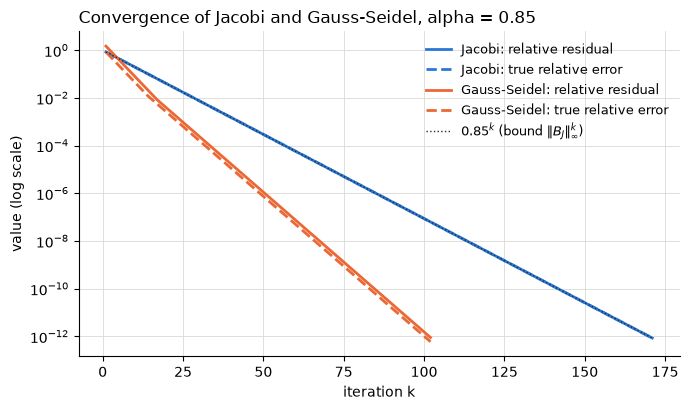

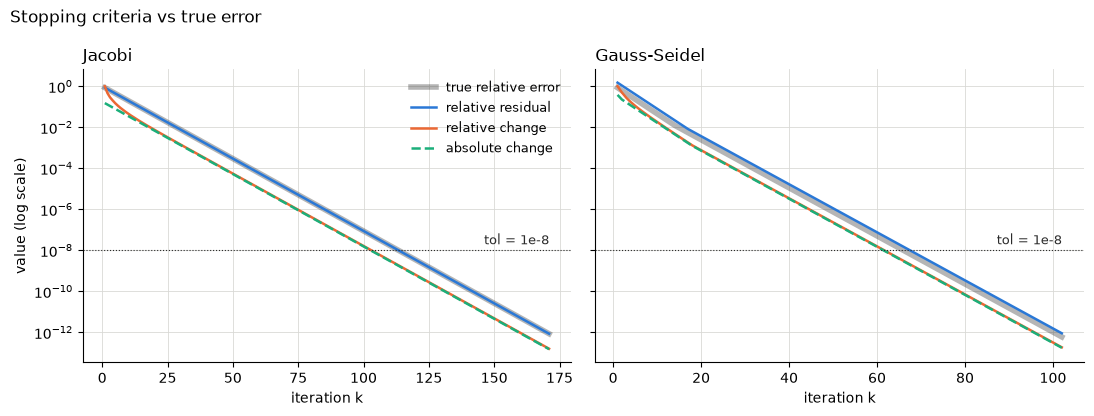

In [20]:
# 4.4 Convergence plots (log scale)

import matplotlib.pyplot as plt

reports_folder = processed_folder.parent.parent / "reports"
blue, orange, aqua, ink, grid_gray = "#2a78d6", "#eb6834", "#1baf7a", "#2b2b2b", "#d9d9d6"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": grid_gray, "grid.linewidth": 0.6, "font.size": 10})

# Figure 1: Jacobi vs Gauss-Seidel, residual (solid) and true error (dashed)
fig, ax = plt.subplots(figsize=(7, 4.2))
for name, color in [("Jacobi", blue), ("Gauss-Seidel", orange)]:
    h = hist[name]
    ax.semilogy(h.iter, h.rel_residual, color=color, lw=2, label=f"{name}: relative residual")
    ax.semilogy(h.iter, h.rel_error, color=color, lw=2, ls="--", label=f"{name}: true relative error")
ax.semilogy(hist["Jacobi"].iter, alpha ** hist["Jacobi"].iter, color=ink, lw=1, ls=":", label=r"$0.85^k$ (bound $\|B_J\|_\infty^k$)")
ax.set_xlabel("iteration k")
ax.set_ylabel("value (log scale)")
ax.set_title("Convergence of Jacobi and Gauss-Seidel, alpha = 0.85", loc="left")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(reports_folder / "m2_convergence_jacobi_vs_gs.png", dpi=200)
plt.show()

# Figure 2: the three criteria vs the true error, one panel per method
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, name in zip(axes, hist):
    h = hist[name]
    # true error drawn first and thicker, so curves that coincide with it stay visible on top
    ax.semilogy(h.iter, h.rel_error, color=ink, lw=4, alpha=0.35, label="true relative error")
    ax.semilogy(h.iter, h.rel_residual, color=blue, lw=1.8, label="relative residual")
    ax.semilogy(h.iter, h.rel_change, color=orange, lw=1.8, label="relative change")
    ax.semilogy(h.iter, h.abs_change, color=aqua, lw=1.8, ls="--", label="absolute change")
    ax.axhline(1e-8, color=ink, lw=0.8, ls=":")
    ax.text(h.iter.iloc[-1], 1.4e-8, "tol = 1e-8", ha="right", va="bottom", fontsize=9, color=ink)
    ax.set_title(name, loc="left")
    ax.set_xlabel("iteration k")
axes[0].set_ylabel("value (log scale)")
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle("Stopping criteria vs true error", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(reports_folder / "m2_stopping_criteria.png", dpi=200)
plt.show()

### Results of Section 4

Figures: `reports/m2_convergence_jacobi_vs_gs.png`, `reports/m2_stopping_criteria.png`. Table: `data/processed/m2_stopping_criteria.csv`.

**All theoretical bounds hold** (24 out of 24 cases in the table), so the true error is always below what the theory predicts from the quantity the criterion monitors.

**The change criteria stop too early: the true error is 2.8 to 5.7 times the tolerance.** For Jacobi the ratio error / tol is about 5, for Gauss-Seidel about 2.9, at every tolerance. This is exactly the warning of the bound $\|e^{(k+1)}\| \le \frac{q}{1-q}\|x^{(k+1)} - x^{(k)}\|$: when the method converges slowly, consecutive iterates are close to each other while still far from $x^*$. The bound is almost sharp for Jacobi (largest observed ratio 5.39 against $q/(1-q) = 5.67$) because the Jacobi error decreases by exactly $q = 0.85$ per step. For Gauss-Seidel the observed ratio is 3.23, which is $\rho/(1-\rho)$ for the observed rate $\rho \approx 0.76$ of Section 3. The norm bound $\|B_{GS}\|_\infty \le 0.85$ is valid but pessimistic for Gauss-Seidel. In practice, if one uses a change criterion, the tolerance should be divided by about $q/(1-q)$ to guarantee the desired error.

**The residual criterion is the reliable one here: the true error is always below the tolerance** (0.85 to 0.95 times tol for Jacobi, 0.56 to 0.59 times for Gauss-Seidel). The worst-case bound $\|e\|/\|x^*\| \le K(A)\,\|r\|/\|b\|$ allows an error up to 12.3 times the relative residual, but the observed ratio is at most 1.00 (Jacobi) and 0.67 (Gauss-Seidel). The condition number bounds the worst possible residual direction, and with a well conditioned matrix ($K_\infty(A) \le 12.3$) the residual is a good proxy of the error. It costs one extra matrix-vector product per iteration, which is why it is the default (`criterion="residual"`).

**Why Jacobi's residual criterion needs exactly 11 more iterations than the change criteria.** With $D = I$, one Jacobi step is $x^{(k+1)} = x^{(k)} + r^{(k)}$, so the change is the previous residual: $\|x^{(k+1)} - x^{(k)}\| = \|r^{(k)}\|$. The two criteria monitor the same sequence, but the residual criterion divides it by $\|b\|_\infty = 0.15$ while the change criteria divide it by $\|x\|_\infty \approx 0.95$ (relative) or by 1 (absolute). The residual criterion is therefore about $1/0.15 \approx 6.7$ times stricter, which costs $\log(6.7) / \log(1/0.85) \approx 11.7$ iterations: 114 against 103 at tol $= 10^{-8}$.

**Absolute vs relative change.** They stop at the same iteration (except by one iteration at $10^{-4}$) only because $\|x\|_\infty \approx 0.95 \approx 1$ with opinions in $[-1, 1]$. The absolute criterion depends on the units of $x$: with opinions on a $[-100, 100]$ scale it would be 100 times stricter, while the relative one would not change. This is why relative criteria are preferred.

**Jacobi vs Gauss-Seidel (Figure 1).** Both curves are straight lines on the log scale, i.e. linear convergence $\|e^{(k)}\| \approx C \rho^k$, with slope $\log 0.85$ for Jacobi (the residual coincides with the bound $0.85^k$) and about $\log 0.76$ for Gauss-Seidel after a faster start at $\alpha^2 = 0.7225$. To reach a true error of $10^{-12}$ Jacobi needs 171 iterations and Gauss-Seidel 102.

## 5. Direct methods and fill-in

**Goal.** Show why a direct method (LU factorization) is not the right tool for this system, by measuring how much memory and time it needs as the network grows, and how much a reordering helps.

**Method.** Gaussian elimination computes $PA = LU$. Even when $A$ is sparse, $L$ and $U$ usually are not: eliminating an unknown $x_k$ updates every row $i$ that has a nonzero in column $k$ by subtracting a multiple of row $k$, so row $i$ inherits the nonzero pattern of row $k$. These new nonzeros are called **fill-in**. We measure it with the fill ratio $(\mathrm{nnz}(L) + \mathrm{nnz}(U)) / \mathrm{nnz}(A)$.

- **Subgraphs.** We take induced subgraphs with $n \in \{500, 1000, 2000, 5000, 10000\}$ nodes: a breadth-first search (on the undirected version of the graph) from the user with the highest degree, keeping the first $n$ nodes reached, and the principal submatrix `A[idx, :][:, idx]`. The submatrix still has unit diagonal and off-diagonal row sums $\le \alpha$, so it stays strictly diagonally dominant and nonsingular. The procedure is deterministic, so no random seed is needed. Starting from the largest hub, these subgraphs are the densest core of the network, i.e. the hardest part for a direct method.
- **Factorizations.** (1) dense LU with partial pivoting, `scipy.linalg.lu_factor` (LAPACK `getrf`, which stores $L$ and $U$ in a single $n \times n$ array), (2) sparse LU `scipy.sparse.linalg.splu` (SuperLU) with the natural column ordering `permc_spec="NATURAL"`, (3) `splu` with the COLAMD column ordering, which reorders the columns to reduce fill-in, (4) `splu` with natural ordering on the RCM-reordered matrix $PAP^T$.
- **Memory.** Dense: $n^2 \times 8$ bytes. Sparse factors: `data`, `indices` and `indptr` arrays of $L$ and $U$, as for CSR.

In [21]:
# 5.1 Induced subgraphs: BFS from the node with the highest degree

import scipy.linalg as sla
from scipy.sparse.csgraph import breadth_first_order

S = (W + W.T).tocsr()  # undirected pattern
start_node = int(np.argmax(np.diff(S.indptr)))
bfs_order = breadth_first_order(S, start_node, directed=False, return_predecessors=False)
print(f"start node {start_node} with {np.diff(S.indptr)[start_node]} neighbours, BFS reaches {len(bfs_order)} of {n} nodes")

sizes = [500, 1000, 2000, 5000, 10000]
subgraphs = {}
for m in sizes:
    idx = np.sort(bfs_order[:m])  # keep the original relative ordering of the users
    A_sub = A[idx, :][:, idx].tocsc()
    off_sum = np.asarray(abs(A_sub).sum(axis=1)).ravel() - np.abs(A_sub.diagonal())
    subgraphs[m] = A_sub
    print(f"n = {m:5d}: nnz = {A_sub.nnz:7d} ({A_sub.nnz / m:.1f} per row), "
          f"strictly diagonally dominant: {np.all(np.abs(A_sub.diagonal()) > off_sum)}")

start node 18 with 3044 neighbours, BFS reaches 75877 of 75879 nodes
n =   500: nnz =   14993 (30.0 per row), strictly diagonally dominant: True
n =  1000: nnz =   30430 (30.4 per row), strictly diagonally dominant: True
n =  2000: nnz =   56089 (28.0 per row), strictly diagonally dominant: True
n =  5000: nnz =  174218 (34.8 per row), strictly diagonally dominant: True
n = 10000: nnz =  291891 (29.2 per row), strictly diagonally dominant: True


In [22]:
# 5.2 LU factorizations: fill-in, memory, time

def factor_mb(lu):
    # memory of the sparse factors L and U (CSC arrays)
    return sum(M.data.nbytes + M.indices.nbytes + M.indptr.nbytes for M in (lu.L, lu.U)) / 1024**2

rows = []
for m, A_sub in subgraphs.items():
    a_mb = (A_sub.data.nbytes + A_sub.indices.nbytes + A_sub.indptr.nbytes) / 1024**2

    # dense LU (LAPACK), L and U in one array
    A_dense = A_sub.toarray()
    start = time.perf_counter()
    LU, piv = sla.lu_factor(A_dense)
    t = time.perf_counter() - start
    nnz_lu = np.count_nonzero(np.tril(LU, -1)) + np.count_nonzero(np.triu(LU))
    rows.append({"n": m, "method": "dense LU", "nnz(A)": A_sub.nnz, "nnz(L)+nnz(U)": nnz_lu,
                 "fill ratio": nnz_lu / A_sub.nnz, "memory MB": m * m * 8 / 1024**2, "A (CSR) MB": a_mb,
                 "time s": t, "row exchanges": int(np.sum(piv != np.arange(m)))})
    del A_dense, LU

    # sparse LU, natural and COLAMD column ordering, and natural on the RCM-reordered matrix
    p_sub = rcm_permutation(A_sub.tocsr())
    cases = [("splu NATURAL", A_sub, "NATURAL"),
             ("splu COLAMD", A_sub, "COLAMD"),
             ("RCM + splu NATURAL", A_sub[p_sub, :][:, p_sub].tocsc(), "NATURAL")]
    for name, M, spec in cases:
        start = time.perf_counter()
        lu = splu(M, permc_spec=spec)
        t = time.perf_counter() - start
        nnz_lu = lu.L.nnz + lu.U.nnz
        rows.append({"n": m, "method": name, "nnz(A)": A_sub.nnz, "nnz(L)+nnz(U)": nnz_lu,
                     "fill ratio": nnz_lu / A_sub.nnz, "memory MB": factor_mb(lu), "A (CSR) MB": a_mb,
                     "time s": t, "row exchanges": int(np.sum(lu.perm_r != lu.perm_c))})  # pivoting beyond the column ordering

lu_table = pd.DataFrame(rows)
lu_table.to_csv(processed_folder / "m2_lu_fill_in.csv", index=False)
pd.set_option("display.float_format", "{:.3g}".format)
lu_table

,n,method,nnz(A),nnz(L)+nnz(U),fill ratio,memory MB,A (CSR) MB,time s,row exchanges
0,500,dense LU,14993,206424,13.8,1.91,0.173,0.000985,0
1,500,splu NATURAL,14993,206924,13.8,2.37,0.173,0.00723,0
2,500,splu COLAMD,14993,134192,8.95,1.54,0.173,0.00547,0
3,500,RCM + splu NATURAL,14993,219819,14.7,2.52,0.173,0.0088,0
4,1000,dense LU,30430,799376,26.3,7.63,0.352,0.00384,0
5,1000,splu NATURAL,30430,800376,26.3,9.17,0.352,0.0345,0
6,1000,splu COLAMD,30430,414854,13.6,4.76,0.352,0.0198,0
7,1000,RCM + splu NATURAL,30430,825076,27.1,9.45,0.352,0.0424,0
8,2000,dense LU,56089,3198464,57,30.5,0.65,0.0242,0
9,2000,splu NATURAL,56089,3200464,57.1,36.6,0.65,0.187,0


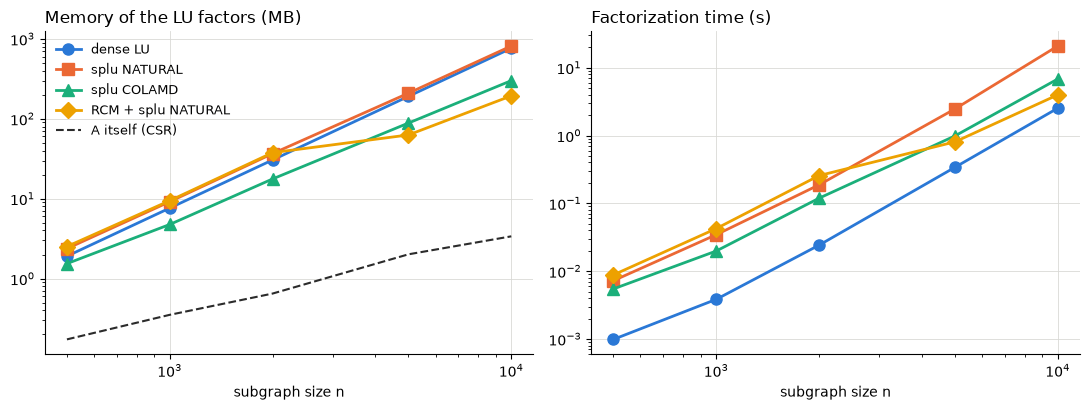

In [23]:
# 5.3 Memory and time vs n (log-log)

yellow = "#eda100"
styles = {"dense LU": (blue, "o"), "splu NATURAL": (orange, "s"),
          "splu COLAMD": (aqua, "^"), "RCM + splu NATURAL": (yellow, "D")}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for name, (color, marker) in styles.items():
    t = lu_table[lu_table.method == name]
    axes[0].loglog(t.n, t["memory MB"], color=color, marker=marker, ms=8, lw=2, label=name)
    axes[1].loglog(t.n, t["time s"], color=color, marker=marker, ms=8, lw=2, label=name)
t = lu_table[lu_table.method == "dense LU"]
axes[0].loglog(t.n, t["A (CSR) MB"], color=ink, lw=1.5, ls="--", label="A itself (CSR)")

axes[0].set_title("Memory of the LU factors (MB)", loc="left")
axes[1].set_title("Factorization time (s)", loc="left")
for ax in axes:
    ax.set_xlabel("subgraph size n")
axes[0].legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(reports_folder / "m2_lu_memory_time.png", dpi=200)
plt.show()

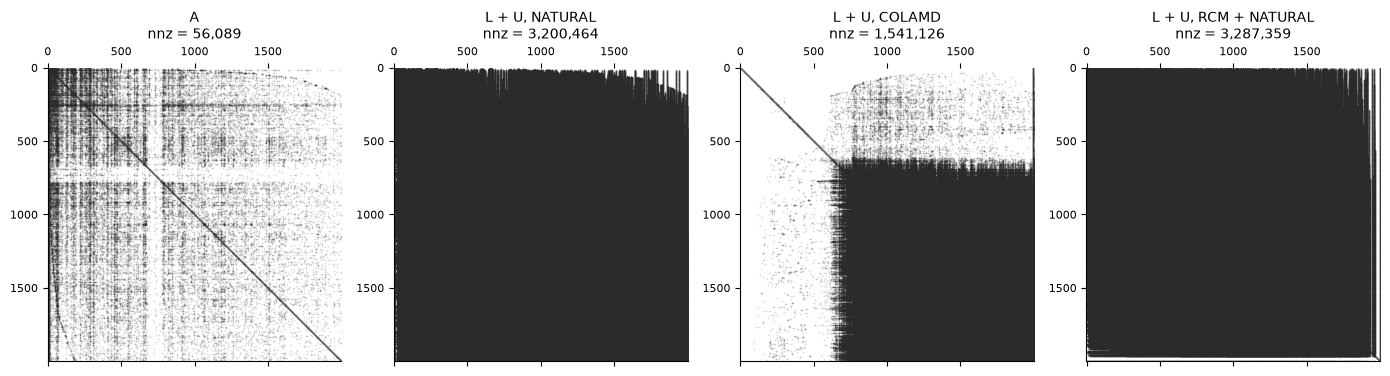

In [24]:
# 5.4 Spy plots of A and of the factors (n = 2000)

m = 2000
A_sub = subgraphs[m]
p_sub = rcm_permutation(A_sub.tocsr())
panels = [("A", A_sub, A_sub.nnz)]
for name, M, spec in [("L + U, NATURAL", A_sub, "NATURAL"),
                      ("L + U, COLAMD", A_sub, "COLAMD"),
                      ("L + U, RCM + NATURAL", A_sub[p_sub, :][:, p_sub].tocsc(), "NATURAL")]:
    lu = splu(M, permc_spec=spec)
    panels.append((name, lu.L + lu.U, lu.L.nnz + lu.U.nnz))  # same count as the table

fig, axes = plt.subplots(1, 4, figsize=(14, 3.9))
for ax, (title, M, nnz_count) in zip(axes, panels):
    ax.spy(M, markersize=0.05, color=ink)
    ax.set_title(f"{title}\nnnz = {nnz_count:,}", fontsize=10)
    ax.tick_params(labelsize=8)
    ax.grid(False)
fig.tight_layout()
fig.savefig(reports_folder / "m2_spy_lu_n2000.png", dpi=200)
plt.show()

In [25]:
# 5.5 Full graph (n = 75,879): dense LU extrapolated, sparse LU measured in Section 1

t10 = lu_table[(lu_table.n == 10000) & (lu_table.method == "dense LU")]["time s"].item()
dense_full_gb = n * n * 8 / 1024**3
print(f"dense LU of the full A: {dense_full_gb:.1f} GB of memory (this laptop has 16 GB), "
      f"time about {t10 * (n / 10000) ** 3 / 60:.0f} min extrapolating the O(n^3) cost from n = 10000")
print("sparse LU of the full A with COLAMD (Section 1): about 150 s, nnz(L)+nnz(U) = 152.8 million, "
      "fill ratio 261, about 1.7 GB")
print(f"band bound for RCM + NATURAL on the full A: nnz(L)+nnz(U) <= n (2 Bw + 1) = {n * (2 * 44499 + 1) / 1e9:.1f} billion entries, "
      f"up to {n * (2 * 44499 + 1) * 12 / 1024**3:.0f} GB, so we did not try it")
print(f"Jacobi on the full A (Section 2): {hist_jac.time_s.sum():.2f} s, memory = A plus a few vectors of length n "
      f"({(A.data.nbytes + A.indices.nbytes + A.indptr.nbytes) / 1024**2 + 4 * n * 8 / 1024**2:.0f} MB)")

dense LU of the full A: 42.9 GB of memory (this laptop has 16 GB), time about 18 min extrapolating the O(n^3) cost from n = 10000
sparse LU of the full A with COLAMD (Section 1): about 150 s, nnz(L)+nnz(U) = 152.8 million, fill ratio 261, about 1.7 GB
band bound for RCM + NATURAL on the full A: nnz(L)+nnz(U) <= n (2 Bw + 1) = 6.8 billion entries, up to 75 GB, so we did not try it
Jacobi on the full A (Section 2): 0.05 s, memory = A plus a few vectors of length n (9 MB)


### Results of Section 5

Figures: `reports/m2_lu_memory_time.png`, `reports/m2_spy_lu_n2000.png`. Table: `data/processed/m2_lu_fill_in.csv`.

**Fill-in grows much faster than the matrix.** With the natural ordering the fill ratio goes from 14 at $n = 500$ to 244 at $n = 10000$. In the log-log plot the memory of $A$ grows linearly with $n$ (slope 1), while the memory of the factors grows like $n^2$ (slope 2): from 2.4 MB to 814 MB while $A$ goes from 0.17 MB to 3.4 MB. Note that these subgraphs are the densest core of the network (about 30 nonzeros per row, against 7.7 in the full $A$), so they are a hard case on purpose.

**With the natural ordering, sparse LU is just a slower dense LU.** `splu` with `NATURAL` produces exactly as many nonzeros as the dense LU (the extra $n$ is the unit diagonal of $L$, which SuperLU stores explicitly), and neither of them performed any row exchange. They compute the same factors, and these factors are almost full: $L + U$ has $71$ million nonzeros out of $10^8$ entries at $n = 10000$. The spy plot shows it: from a scattered $A$ with 56,089 nonzeros we get a practically full square. Once the factors are full, the sparse format only adds overhead: 7% more memory for the index arrays, and 8 times more time than LAPACK (2.5 s against 21 s at $n = 10000$), which works on contiguous dense blocks.

**Reordering helps, but not enough.**
- **COLAMD** reduces the fill by a factor 1.5 to 2.7 (90 instead of 244 at $n = 10000$). The spy plot shows how: it moves the hubs (the dense columns) to the end, so the first $\approx 650$ columns of the low-degree users are eliminated almost without fill, and all the fill is concentrated in a dense trailing block where the hubs interact.
- **RCM** is useless on the small subgraphs (slightly worse than natural): in the dense core every node is close to every other, so no ordering makes the matrix narrow-banded. It becomes the best ordering for $n \ge 5000$ (58 at $n = 10000$, 194 MB).
- Even in the best case, the factors take 57 times the memory of $A$, and the ratio keeps growing with $n$.

**On the full graph** ($n = 75{,}879$):

| method | memory | time |
|---|---|---|
| dense LU | 42.9 GB, does not fit in 16 GB of RAM | about 18 min (extrapolated $O(n^3)$) |
| sparse LU, COLAMD (Section 1) | about 1.7 GB, fill ratio 261 | about 150 s |
| RCM + sparse LU, NATURAL | up to 75 GB by the band bound $n(2\,Bw + 1)$, not attempted | |
| **Jacobi**, tol $10^{-8}$ (Section 2) | **about 9 MB** ($A$ plus a few vectors) | **about 0.05 s** |

**Why iterative methods are preferred here.**
1. **Memory.** Jacobi and Gauss-Seidel only need $A$ in CSR and a few vectors, $O(\mathrm{nnz}(A))$. There is no fill-in because $A$ is never modified, it is only multiplied by vectors.
2. **Time.** One iteration costs one sparse matrix-vector product, and thanks to the strict diagonal dominance at most about 114 iterations are needed for $10^{-8}$. The full solve is about 3000 times faster than the sparse LU.
3. **Accuracy.** A direct method gives the solution to machine precision, but opinions do not need 15 digits. The stopping criterion lets us choose the accuracy we need and pay only for that.
4. **The matrix changes with $\alpha$.** In the dogmatism study (Member 3) $A = I - \alpha W$ changes at every value of $\alpha$, so an LU would have to be recomputed from scratch each time, while an iterative method can even start from the solution at the previous $\alpha$.

The one case where LU could pay off is many right-hand sides with the same $A$ (e.g. many topics $s$ at fixed $\alpha$), since the factors can be reused and each extra solve costs only two triangular solves. Even then, the 150 s and 1.7 GB of the factorization are worth about 3000 Jacobi solves.